In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.differentiate import jacobian

In [15]:
##### calibration
std_fs = 0.15 * 0.05 / 100 # full scale error from manual
std_u_temp = 0.08 / 1000 # another error from manual
std_U = std_fs + std_u_temp # error of U general

# lab pressure calibration point
mmPerHg = 719 #+-1 (mm / Hg) with correction for pressure
U_lab = 0.12755 # 0.12795 measured value in lab (but probalby a bit off) # measurement
p_lab = mmPerHg * 133.322 / 100000 # measurement  2.72 mm / Hg  716 reading at 21.5°
std_p_lab = 1 * 133.322 / 100000 # estimation

# low-pressure (# evacuate pump (7-10min))
U_2 = (-1) * 0.00526 # measurement
p_2 = 0.0001 # +- 0.0001 bar (manual)
std_p_2 = 0.0001

print('p_lab =', p_lab, '+-', std_p_lab)

p_lab = 0.9585851799999999 +- 0.00133322


In [16]:
def f_c (data):
    pl = data[0]
    p2 = data[1]
    ul = data[2]
    u2 = data[3]
    return (pl - p2) / (ul - u2)

def f_p0 (data):
    pl = data[0]
    p2 = data[1]
    ul = data[2]
    u2 = data[3]
    return pl - (pl - p2) / (1 - u2 / ul)

def f_pr (data):
    pl = data[0]
    p2 = data[1]
    ul = data[2]
    u2 = data[3]

    u = data[4]

    c = f_c(data[:-1])
    p0 = f_p0(data[:-1])
    return p0 + u * c

C = 7.216965439349447 +- 0.015595703215008814
p_0 = 0.03806123821097818 +- 0.0010808101074841103


Text(0, 0.5, 'pressure [Bar]')

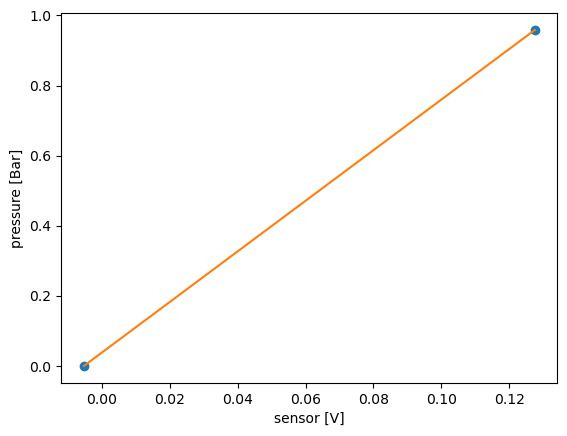

In [17]:
point_c = np.array([p_lab, p_2, U_lab, U_2])
sigma_c = np.array([std_p_lab, std_p_2, std_U, std_U])
point_p0 = point_c
sigma_p0 = sigma_c
C = f_c(point_c)
p_0 = f_p0(point_p0)

#error prop
jac_c = jacobian(f_c, point_c).df
std_c = np.sqrt(jac_c**2 @ sigma_c.transpose()**2)
jac_p0 = jacobian(f_p0, point_p0).df
std_p0 = np.sqrt(jac_p0**2 @ sigma_p0.transpose()**2)

#print
print('C =', C, '+-', std_c)
print('p_0 =', p_0, '+-', std_p0)

#plot
x = np.array([U_lab, U_2])
y = np.array([p_lab, p_2])
linspace = np.linspace(np.min(x), np.max(x), 20)
points = np.zeros((len(linspace), 5))
points[:,: 4] = point_c
points[:, 4] = linspace
plt.plot(x, y, marker='o', linestyle='')
plt.plot(linspace, f_pr(points.transpose()))
plt.xlabel('sensor [V]')
plt.ylabel('pressure [Bar]')

In [18]:
##### absolute zero
# evacuate pump (7-10min (maybe already done))
# fill with helium for at least two minutes
# repeat procedure once

In [20]:
# boiling water (close opening after heating)
U_k = 0.12755 # measurment
t_k = 98.455 # table relation with pressure #+-1
std_t_k = 1 # estimation
point_k = np.array([p_lab, p_2, U_lab, U_2, U_k])
sigma_k = np.array([std_p_lab, std_p_2, std_U, std_U, std_U])

# calculation
p_k = f_pr(point_k)

# error prop
jac_pk = jacobian(f_pr, point_k).df
std_p_k = np.sqrt(jac_pk**2 @ sigma_k.transpose()**2)

print('p_k =', p_k, '+-', std_p_k)

p_k = 0.95858518 +- 0.0020688499523207277


In [24]:
# ice water
# make cold ice water wait ca 2min
U_e = 0.0925 # measurment
t_e = 0 # temperature ice-water
std_t_e = 1 # estimation
point_e = np.array([p_lab, p_2, U_lab, U_2, U_e])
sigma_e = np.array([std_p_lab, std_p_2, std_U, std_U, std_U])

# calculation
p_e = f_pr(point_e)

# error prop
jac_pe = jacobian(f_pr, point_e).df
std_p_e = np.sqrt(jac_pe**2 @ sigma_e.transpose()**2)

print('p_e =', p_e, '+-', std_p_e)

p_e = 0.7056305413508019 +- 0.0017263468123287621


In [33]:
def f_t0approx (data):
    pl = data[0]
    p2 = data[1]
    ul = data[2]
    u2 = data[3]

    uk = data[4]
    ue = data[5]
    pk = f_pr(data[:5])
    pe = f_pr(data[[0, 1, 2, 3, 5]])

    tk = data[6]

    return (-1) * pe * tk / (pk - pe)

In [39]:
##### calculations:
point_t0approx = np.array([p_lab, p_2, U_lab, U_2, U_k, U_e, t_k])
sigma_t0approx = np.array([std_p_lab, std_p_2, std_U, std_U, std_U, std_U, std_t_k])

# calculation
t_0_approx = f_t0approx(point_t0approx)

# error prop
jac_t0approx = jacobian(f_t0approx, point_t0approx).df
std_t_0_approx = np.sqrt(jac_t0approx**2 @ sigma_t0approx.transpose()**2)



print('t_0_approx =', t_0_approx, '+-', std_t_0_approx)

t_0_approx = -274.6455068769835 +- 3.488579602109813


In [ ]:
epsilon = 10**(-3)
gamma = 10**(-5)

def f_t0(data):
    pl = data[0]
    p2 = data[1]
    ul = data[2]
    u2 = data[3]

    uk = data[4]
    ue = data[5]
    pk = f_pr(data[:5])
    pe = f_pr(data[[0, 1, 2, 3, 5]])

    tk = data[6]
    te = data[7]
    tl = data[8]

    aa = (1 + epsilon) * pe - (1 + epsilon + gamma * tk) * pk
    bb = epsilon * (pk - pe) * (te + tk) + (1 + gamma * tk) * pk * (te + tl) - pe * (tl + tk)
    cc = pe * tl * tk + epsilon * (pe - pk) * te * tk - (1 + gamma * tk) * pk * te * tl

    return ((-1) * bb + np.sqrt(bb**2 - 4 * aa * cc)) / (2 * aa)


In [52]:
t_lab = 21.5 # measurment +-1
std_t_lab = 1 # estimation
point_t0 = np.array([p_lab, p_2, U_lab, U_2, U_k, U_e, t_k, t_e, t_lab])
simga_t0 = np.array([std_p_lab, std_p_2, std_U, std_U, std_U, std_U, std_t_k, std_t_e, std_t_lab])

# calculation
t_0 = f_t0(point_t0)

# error prop
jac_t0 = jacobian(f_t0, point_t0).df
std_t_0 = np.sqrt(jac_t0**2 @ simga_t0.transpose()**2)

print('t_0 =', t_0, '+-', std_t_0)

t_0 = -273.28126955190146 +- 5.121736994253478


In [56]:
##### liquid nitrogen
U_LN2 = 0.02465 # measurement
point_ln2 = np.array([p_lab, p_2, U_lab, U_2, U_LN2])
sigma_ln2 = np.array([std_p_lab, std_p_2, std_U, std_U, std_U])

# calculation
p_LN2 = f_pr(point_ln2)

# error prop
jac_pln2 = jacobian(f_pr, point_ln2).df
std_p_LN2 = np.sqrt(jac_pln2**2 @ sigma_ln2.transpose()**2)

print(p_LN2, '+-', std_p_LN2)

0.21595943629094203 +- 0.0014704182554508023


In [66]:
def f_tln2approx (data):
    pl = data[0]
    p2 = data[1]
    ul = data[2]
    u2 = data[3]

    uk = data[4]
    ue = data[5]
    pe = f_pr(data[[0, 1, 2, 3, 5]])

    tk = data[6]
    te = data[7]
    tl = data[8]

    t0 = f_t0(data[0:9])

    uln2 = data[9]
    pln2 = f_pr(data[[0, 1, 2, 3, 9]])

    return (1 - pln2 / pe) * t0


In [70]:
point_tln2approx = np.array([p_lab, p_2, U_lab, U_2, U_k, U_e, t_k, t_e, t_lab, U_LN2])
sigma_tln2approx = np.array([std_p_lab, std_p_2, std_U, std_U, std_U, std_U, std_t_k, std_t_e, std_t_lab, std_U])

# calculation
t_LN2_approx = f_tln2approx(point_tln2approx)

# error prop
jac_tln2approx = jacobian(f_tln2approx, point_tln2approx).df
print(jac_tln2approx**2 @ sigma_tln2approx.transpose()**2)

std_t_LN2_approx = np.sqrt(((t_0) / p_e * (-1) * std_p_LN2)**2
                        + (p_LN2 * t_0 / p_e**2 * std_p_e)**2
                        + ((1 - p_LN2 / p_e) * std_t_0)**2)

print(t_LN2_approx, '+-', std_t_LN2_approx)

13.048447530900562
-189.6430687332082 +- 3.605364719757472


In [39]:
def ft_ln2 (data):
    pl = data[0]
    p2 = data[1]
    ul = data[2]
    u2 = data[3]

    uk = data[4]
    ue = data[5]
    uln2 = data[6]

    pk = pr(uk, pl, p2, ul, u2)
    pe = pr(ue, pl, p2, ul, u2)
    pln2 = pr(uln2, pl, p2, ul, u2)

    tk = data[7]
    te = data[8]
    tl = data[9]

    idk = np.array([pl, p2, ul, u2, uk, ue, tk, te, tl])
    t0 = ft0(idk)
    
    AAAAA = pe / (te - t0) + epsilon * (pe - pln2) / (tl - t0)

    return (AAAAA * t0 + pln2) / (AAAAA - gamma * pln2)

def t_LN22 (data):
    pe = data[0]
    pk = data[1]
    pln2 = data[2]
    te = data[3]
    tk = data[4]
    tl = data[5]

    idk = np.array([pk, pe, tk, te, tl])
    t0 = t_00(idk)
    
    AAAAA = pe / (te - t0) + epsilon * (pe - pln2) / (tl - t0)

    return (AAAAA * t0 + pln2) / (AAAAA - gamma * pln2)

In [40]:
zz = np.array([p_e, p_k, p_LN2, t_e, t_k, t_lab])
std_zz = np.array([std_p_e, std_p_k, std_p_LN2, std_t_e, std_t_k, std_t_lab])

zzzz = np.array([p_lab, p_2, U_lab, U_2, U_k, U_e, U_LN2, t_k, t_e, t_lab])
std_zzzz = np.array([std_p_lab, std_p_2, std_U, std_U, std_U, std_U, std_U, std_t_k, std_t_e, std_t_lab])

t_LN2 = t_LN22(zz)

jacc = jacobian(t_LN22, zz).df
std_t_LN2 = np.sqrt(jacc**2 @ std_zz.transpose()**2)

jacccc = jacobian(ft_ln2, zzzz).df
std_t_LN222 = np.sqrt(jacccc**2 @ std_zzzz.transpose()**2)

print(t_LN2, '+-', std_t_LN2)
print(ft_ln2(zzzz), '+-', std_t_LN222)

#3.810765165962369

-189.85553116990928 +- 4.343240938510312
-189.85553116990928 +- 3.8463640459479818
